In [1]:
import pandas as pd
import os
import matplotlib.pyplot as plt

In [2]:
# Read the cleaned weather dataset

df = pd.read_csv("../data/processed/pakistan_weather_2025.csv")

df.head()

,date,city,temp_max,temp_min,precipitation
0,2025-01-01,Karachi,26.2,15.2,0.0
1,2025-01-02,Karachi,25.6,14.8,0.0
2,2025-01-03,Karachi,24.6,14.8,0.0
3,2025-01-04,Karachi,24.2,17.2,0.0
4,2025-01-05,Karachi,22.5,13.0,0.0


In [3]:
# Check the basic information of the dataset

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1825 entries, 0 to 1824
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           1825 non-null   str    
 1   city           1825 non-null   str    
 2   temp_max       1825 non-null   float64
 3   temp_min       1825 non-null   float64
 4   precipitation  1825 non-null   float64
dtypes: float64(3), str(2)
memory usage: 71.4 KB


In [4]:
# Check missing values in the dataset

df.isna().sum()

date             0
city             0
temp_max         0
temp_min         0
precipitation    0
dtype: int64

In [5]:
# Identify the average maximum temperature of each city

max_temp = df.groupby("city").agg(
    Average_max_temp=("temp_max", "mean")
).sort_values("Average_max_temp", ascending=False)

max_temp.round(2)

,Average_max_temp
city,
Karachi,30.91
Lahore,30.11
Peshawar,29.11
Islamabad,27.81
Quetta,25.42


In [6]:
# Find out the city with the highest and lowest average temperature

max_temp.idxmax()

Average_max_temp    Karachi
dtype: str

In [7]:
max_temp.idxmin()

Average_max_temp    Quetta
dtype: str

In [8]:
# Calculate the total precipitation of each city

high_rain = df.groupby("city").agg(
    Total_precipitation=("precipitation", "sum")
).sort_values("Total_precipitation", ascending=False)

high_rain.round(2)

,Total_precipitation
city,
Islamabad,1188.2
Lahore,931.9
Peshawar,665.3
Karachi,341.0
Quetta,179.4


In [10]:
# Find out the cities with the highest and lowest precipitation

high_rain["Total_precipitation"].idxmax()
high_rain["Total_precipitation"].idxmin()

'Quetta'

In [11]:
# Calculate the difference between maximum and minimum precipitation

difference = (
    high_rain["Total_precipitation"].max()
    - high_rain["Total_precipitation"].min()
)

print(round(difference, 2))

1008.8


In [12]:
# Convert date column into datetime format and extract month

df["date"] = pd.to_datetime(df["date"])
df["month"] = df["date"].dt.month

df.head()

,date,city,temp_max,temp_min,precipitation,month
0,2025-01-01,Karachi,26.2,15.2,0.0,1
1,2025-01-02,Karachi,25.6,14.8,0.0,1
2,2025-01-03,Karachi,24.6,14.8,0.0,1
3,2025-01-04,Karachi,24.2,17.2,0.0,1
4,2025-01-05,Karachi,22.5,13.0,0.0,1


In [13]:
# Calculate the average maximum temperature of each city in every month

monthly_temp = df.groupby(["city", "month"]).agg(
    Average_temp_in_month=("temp_max", "mean")
).reset_index()

monthly_temp.round(2)

,city,month,Average_temp_in_month
0,Islamabad,1,18.65
1,Islamabad,2,20.38
2,Islamabad,3,23.52
3,Islamabad,4,33.66
4,Islamabad,5,35.47
5,Islamabad,6,37.32
6,Islamabad,7,31.99
7,Islamabad,8,31.29
8,Islamabad,9,32.39
9,Islamabad,10,27.50


In [14]:
# Find out the hottest month of each city

hottest_months = monthly_temp.loc[
    monthly_temp.groupby("city")["Average_temp_in_month"].idxmax()
]

hottest_months.round(2)

,city,month,Average_temp_in_month
5,Islamabad,6,37.32
15,Karachi,4,34.22
29,Lahore,6,38.97
41,Peshawar,6,40.04
54,Quetta,7,36.52


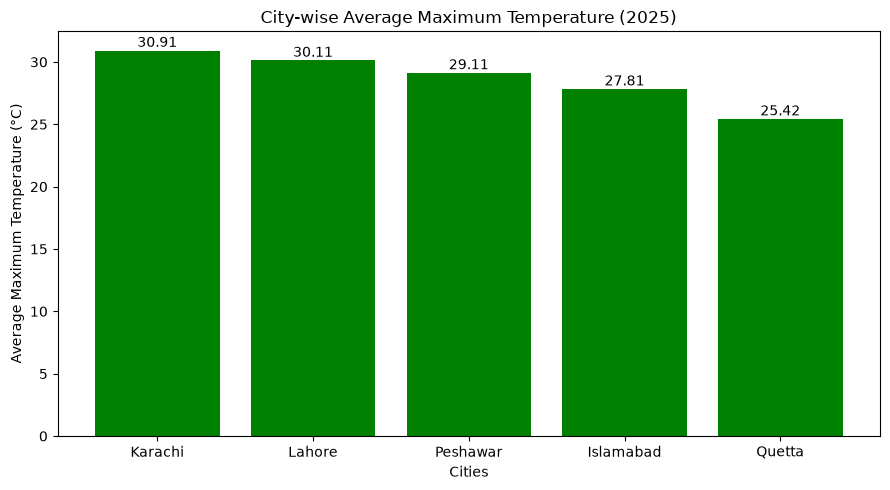

In [15]:
# Visualization of average maximum temperature of each city

plt.figure(figsize=(9, 5))

plt.bar(
    max_temp.index,
    max_temp["Average_max_temp"],
    color="green"
)

plt.title("City-wise Average Maximum Temperature (2025)")
plt.xlabel("Cities")
plt.ylabel("Average Maximum Temperature (°C)")

for i in range(len(max_temp)):
    plt.text(
        i,
        max_temp["Average_max_temp"].iloc[i] + 0.3,
        round(max_temp["Average_max_temp"].iloc[i], 2),
        ha="center"
    )

plt.tight_layout()
plt.show()

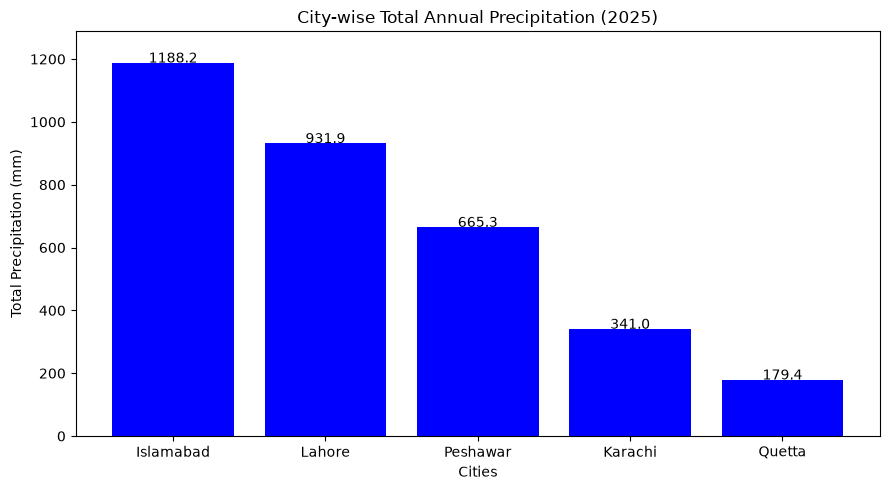

In [16]:
# Visualization of total annual precipitation of each city

plt.figure(figsize=(9, 5))

plt.bar(
    high_rain.index,
    high_rain["Total_precipitation"],
    color="blue"
)

plt.title("City-wise Total Annual Precipitation (2025)")
plt.xlabel("Cities")
plt.ylabel("Total Precipitation (mm)")

for i in range(len(high_rain)):
    plt.text(
        i,
        high_rain["Total_precipitation"].iloc[i] + 0.6,
        round(high_rain["Total_precipitation"].iloc[i], 2),
        ha="center"
    )

plt.ylim(0, high_rain["Total_precipitation"].max() + 100)
plt.tight_layout()
plt.show()

In [17]:
# Separate monthly temperature data for each city

karachi_data = monthly_temp[monthly_temp["city"] == "Karachi"]
lahore_data = monthly_temp[monthly_temp["city"] == "Lahore"]
islamabad_data = monthly_temp[monthly_temp["city"] == "Islamabad"]
peshawar_data = monthly_temp[monthly_temp["city"] == "Peshawar"]
quetta_data = monthly_temp[monthly_temp["city"] == "Quetta"]

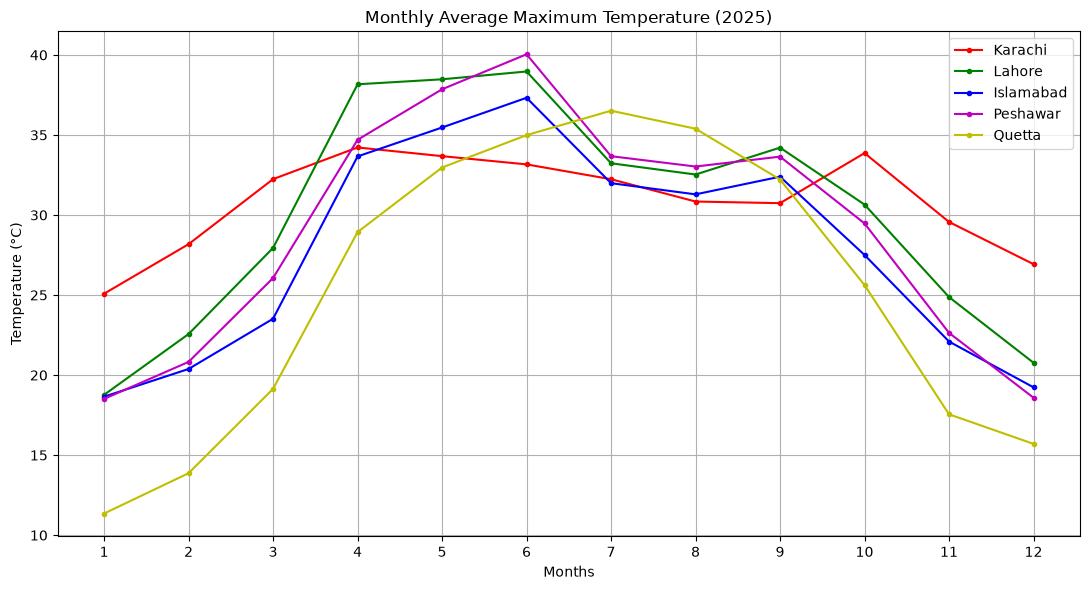

In [18]:
# Visualization of monthly average maximum temperature trends

plt.figure(figsize=(11, 6))

plt.plot(
    karachi_data["month"],
    karachi_data["Average_temp_in_month"],
    ".-r",
    label="Karachi"
)

plt.plot(
    lahore_data["month"],
    lahore_data["Average_temp_in_month"],
    ".-g",
    label="Lahore"
)

plt.plot(
    islamabad_data["month"],
    islamabad_data["Average_temp_in_month"],
    ".-b",
    label="Islamabad"
)

plt.plot(
    peshawar_data["month"],
    peshawar_data["Average_temp_in_month"],
    ".-m",
    label="Peshawar"
)

plt.plot(
    quetta_data["month"],
    quetta_data["Average_temp_in_month"],
    ".-y",
    label="Quetta"
)

plt.title("Monthly Average Maximum Temperature (2025)")
plt.xlabel("Months")
plt.ylabel("Temperature (°C)")
plt.xticks(range(1, 13))
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

In [19]:
# Insights of this Analysis

# 1. Karachi: Temperatures remain relatively stable throughout the year,
# without the sharp seasonal changes seen in other cities.

# 2. Lahore: Temperatures peak around June.

# 3. Islamabad: The highest monthly average maximum temperature occurs in June.

# 4. Peshawar: Temperatures peak in June, reaching approximately 40°C.

# 5. Quetta: Temperatures peak between June and July,
# followed by a sharp decline.